# 01 · Relevanz-Schwelle und Boost/Buff

**Ziel:** Ampel-Schwellen der Triage aus Daten herleiten statt raten, und festlegen, wie stark ein Klick auf
**Boost** („relevant für Suva“) bzw. **Buff** („nicht relevant“) den Score verschiebt.

Logik liegt in `src/hack_apertus_coffee_exe/eval/relevance.py`, das Notebook ruft sie nur auf.

## Leitfragen (Rubberducking)

| # | Frage | Wie wir sie beantworten | Status |
|---|---|---|---|
| F1 | Ab welchem Score ist ein Urteil **grün** (Suva fasst es zusammen)? | Score der bekannten Suva-Fälle, tiefster Wert = Kandidat (Recall 100 %) | in Arbeit |
| F2 | Wo beginnt **gelb** (mittlere Relevanz)? | Streuung (σ) der Suva-Fälle → z. B. Mittelwert − k·σ | in Arbeit |
| F3 | Wie stark verschiebt **Boost/Buff** den Score? | Abstand und Streuung Referenzen vs. Rest | Hypothese |
| F4 | Wie **lernt** die Pipeline aus dem Klick? | Klick → `set_reference_flags` → nächstes Scoring; simulieren | offen |
| F5 | Welchen Score nehmen wir: nur Embedding oder `final_score` mit LLM? | Erst Embedding (gratis, alle 6000 Urteile), LLM auf Stichprobe | offen |

**Regeln für die Auswertung**
- *Leakage-frei:* Ein Quartal wird nur mit Suva-Fällen bewertet, die **vor** dem Quartal entschieden wurden (`score_candidates`, `ref_date_to` = Tag vor Quartalsbeginn).
- Gelabelt sind nur **2025-Q4 und 2026-Q1** (Excel `BG_Urteile_2025_Q4_2026_Q1.xlsx`). 2026-Q2 ist der Abgabe-Zeitraum ohne Labels.


In [1]:
import os
from pathlib import Path

# Pfade relativ zum Projekt-Root (data/, results/), egal von wo das Notebook startet
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.relevance import (
    LABELLED_QUARTERS, open_vectordb, score_quarters, threshold_candidates, evaluate_threshold, best_f_beta,
)

pd.set_option("display.precision", 2)
REF, OTHER = "#257de0", "#9c9c9c"   # Suva-Fälle blau, alle anderen grau
db = open_vectordb()   # liest gespeicherte Vektoren, kein PyTorch nötig

## 1. Datenbestand

In [2]:
meta = pd.DataFrame(db.query())
meta["month"] = meta["decision_date"].str[:7]
inventory = meta.groupby("month").agg(judgements=("case_id", "size"), suva_refs=("is_reference", "sum"))
print(f"{len(meta)} Urteile, {int(meta.is_reference.sum())} Suva-Referenzen, "
      f"{int(meta.is_negative_reference.sum())} Negativ-Referenzen")
print("FTS-Index vorhanden:", db.fts_path.exists(), "(ohne FTS fehlt der Volltext-Bonus im Hybrid-Score)")
inventory

6053 Urteile, 82 Suva-Referenzen, 0 Negativ-Referenzen
FTS-Index vorhanden: False (ohne FTS fehlt der Volltext-Bonus im Hybrid-Score)


,judgements,suva_refs
month,,
2025-07,2,2
2025-08,14,14
2025-09,7,7
2025-10,711,5
2025-11,636,13
2025-12,583,10
2026-01,609,14
2026-02,668,5
2026-03,727,12


**Beobachtungen**
- Jul–Sep 2025 enthält nur die Suva-Fälle selbst (nachgeladen über `fetch_reference_cases`), kein vollständiger Crawl. Sie dienen als Referenzen für Q4.
- Für 2025-Q4 stehen also 23 frühere Referenzen zur Verfügung, für 2026-Q1 schon 51.
- Es gibt noch **keine Negativ-Referenzen**, Buff hat heute also keine Datenbasis.


## 2. Leakage-freies Scoring pro Quartal

In [3]:
scores = score_quarters(db)
scores.groupby(["quarter", "is_reference"])["score"].describe()

count   mean   std    min    25%    50%    75%    max
quarter is_reference                                                        
2025-Q4 False         1902.0  78.65  2.17  74.47  77.49  78.24  79.14  91.95
        True            28.0  89.26  3.95  80.72  85.29  91.33  91.92  92.82
2026-Q1 False         1973.0  79.26  2.50  74.30  78.05  78.75  79.61  93.07
        True            31.0  90.01  4.04  78.51  88.72  91.98  92.40  92.82

## 3. Verteilung: Suva-Fälle vs. alle anderen

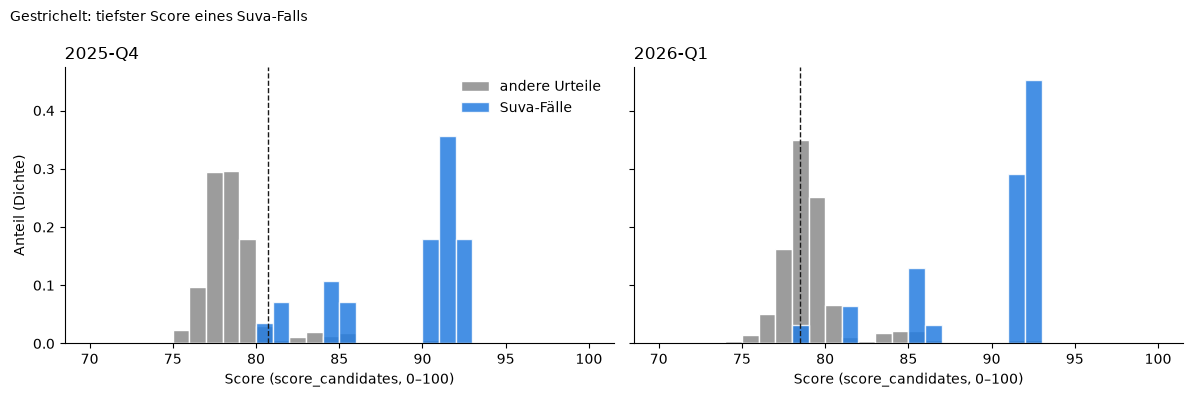

In [4]:
fig, axes = plt.subplots(1, len(LABELLED_QUARTERS), figsize=(12, 4), sharey=True)
bins = np.arange(70, 100.5, 1)
for ax, (q, part) in zip(axes, scores.groupby("quarter")):
    ax.hist(part.loc[~part.is_reference, "score"], bins=bins, density=True, color=OTHER, label="andere Urteile",
            edgecolor="white", linewidth=1)
    ax.hist(part.loc[part.is_reference, "score"], bins=bins, density=True, color=REF, alpha=0.85,
            label="Suva-Fälle", edgecolor="white", linewidth=1)
    ax.axvline(part.loc[part.is_reference, "score"].min(), color="#191919", linewidth=1, linestyle="--")
    ax.set_title(q, loc="left")
    ax.set_xlabel("Score (score_candidates, 0–100)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anteil (Dichte)")
axes[0].legend(frameon=False)
fig.suptitle("Gestrichelt: tiefster Score eines Suva-Falls", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
plt.show()

**Beobachtung:** Die Skala ist stark gestaucht. Fast alle Urteile liegen zwischen 75 und 95.
Die heutigen Schwellen aus `configs/triage.json` (grün ≥ 60, gelb ≥ 40) machen damit **jedes Urteil grün**.


## 4. Schwellen-Kandidaten (F1, F2)

In [5]:
rows = []
for q, part in [*scores.groupby("quarter"), ("beide", scores)]:
    for name, thr in threshold_candidates(part.loc[part.is_reference, "score"]).items():
        rows.append({"quarter": q, "candidate": name, **evaluate_threshold(part, thr)})
    rows.append({"quarter": q, "candidate": "best F2", **best_f_beta(part, beta=2)})
    rows.append({"quarter": q, "candidate": "config 60", **evaluate_threshold(part, 60.0)})
cand = pd.DataFrame(rows).drop(columns="f_beta", errors="ignore")
cand.to_csv("results/tables/relevance_threshold_candidates.csv", index=False)
cand

,quarter,candidate,threshold,flagged,flagged_share,recall,precision
0,2025-Q4,min,80.72,184,0.10,1.00,0.15
1,2025-Q4,p05,81.33,168,0.09,0.93,0.15
2,2025-Q4,p10,83.28,131,0.07,0.89,0.19
3,2025-Q4,mean-1sd,85.31,66,0.03,0.75,0.32
4,2025-Q4,mean-2sd,81.36,167,0.09,0.93,0.16
5,2025-Q4,mean-3sd,77.40,1495,0.77,1.00,0.02
6,2025-Q4,best F2,90.33,34,0.02,0.71,0.59
7,2025-Q4,config 60,60.00,1930,1.00,1.00,0.01
8,2026-Q1,min,78.51,1211,0.60,1.00,0.03
9,2026-Q1,p05,81.32,227,0.11,0.94,0.13


Lesart: `flagged` = so viele Urteile müsste Suva pro Quartal anschauen; `recall` = Anteil der Suva-Fälle, die wir damit finden.
Die Challenge verlangt, dass **alle** von Suva zusammengefassten Urteile erkannt werden → Recall 100 % ist das Ziel, also `min`.


## 5. Ausreisser: die am tiefsten bewerteten Suva-Fälle

In [6]:
(scores[scores.is_reference]
 .sort_values("score")
 .head(8)[["quarter", "case_id", "decision_date", "division", "subject", "score", "rank", "max_similarity"]])

,quarter,case_id,decision_date,division,subject,score,rank,max_similarity
3138,2026-Q1,9C_65/2025,2026-01-29,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Assicurazione per l'invalidità (diniego di giu...,78.51,1206,0.96
183,2025-Q4,9C_382/2025,2025-11-25,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Invalidenversicherung,80.72,183,0.97
169,2025-Q4,9C_699/2024,2025-10-24,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Invalidenversicherung (Invalidenrente),81.29,170,0.97
2157,2026-Q1,9C_145/2025,2026-03-16,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Invalidenversicherung,81.31,228,0.97
2156,2026-Q1,9C_311/2025,2026-03-18,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Invalidenversicherung,81.33,227,0.97
165,2025-Q4,9C_690/2024,2025-10-29,IV. Öffentlich-rechtliche Abteilung (II. Sozia...,Assurance-invalidité (évaluation de l'invalidité),81.39,166,0.97
97,2025-Q4,8C_61/2025,2025-10-09,III. Öffentlich-rechtliche Abteilung (I. Sozia...,Invalidenversicherung (Drittauszahlung),84.09,98,0.95
90,2025-Q4,8C_531/2025,2025-11-14,III. Öffentlich-rechtliche Abteilung (I. Sozia...,Invalidenversicherung (Hilflosenentschädigung),84.34,91,0.96


### Woher kommen die zwei Gruppen? Score nach Kammer

In [7]:
scores["kammer"] = scores["case_id"].str.extract(r"^(\d+[A-Z])_")[0]
scores["unfall_im_sachgebiet"] = scores["subject"].fillna("").str.lower().str.contains("unfall|accident|infortun|uvg|laa|lainf")
(scores.groupby(["kammer", "unfall_im_sachgebiet", "is_reference"])["score"]
 .agg(["count", "mean", "min", "max"])
 .query("count >= 5 or is_reference"))

,,,count,mean,min,max
kammer,unfall_im_sachgebiet,is_reference,,,,
1C,False,False,360,78.07,74.32,80.76
1D,False,False,8,79.04,77.56,80.36
1F,False,False,11,78.18,77.75,78.69
2C,False,False,375,78.81,74.41,80.81
2D,False,False,17,78.43,76.63,80.33
2F,False,False,23,78.04,76.26,78.84
4A,False,False,349,78.55,75.02,80.85
4D,False,False,137,77.73,74.65,79.72
4F,False,False,32,77.73,75.69,78.78


`score_candidates` addiert fest **+0.05 für 8C** und **+0.08 für Unfall im Sachgebiet** (≈ +4 bzw. +7 Score-Punkte).
Die Lücke zwischen den beiden Gruppen ist also zu grossen Teilen dieser Bonus, nicht die Ähnlichkeit.
Suva fasst aber auch **9C-Fälle (Invalidenversicherung)** zusammen; die bekommen keinen Bonus und landen tief.


Diese wenigen Fälle bestimmen allein die `min`-Schwelle. Fragen dazu:
- Sind es echte Suva-Fälle oder falsch zugeordnete IDs (z. B. 9C statt 8C, verbundene Verfahren)?
- Wenn echt: lieber Schwelle senken (mehr Arbeit) oder bewusst verpassen und im Report nennen?


## 6. Top 30 (Erfolgskriterium der Challenge)

In [8]:
top30 = (scores.assign(top30=scores["rank"] <= 30)
         .groupby("quarter")
         .apply(lambda p: pd.Series({"suva_faelle": int(p.is_reference.sum()),
                                     "davon_in_top30": int((p.is_reference & p.top30).sum())}), include_groups=False))
top30["recall@30"] = top30.davon_in_top30 / top30.suva_faelle
top30

,suva_faelle,davon_in_top30,recall@30
quarter,,,
2025-Q4,28,19,0.68
2026-Q1,31,16,0.52


## 7. Streuung → gelb und Boost/Buff (F2, F3, erste Hypothese)

In [9]:
stats = scores.groupby(["quarter", "is_reference"])["score"].agg(["mean", "std"]).unstack()
stats.columns = [f"{a}_{'suva' if b else 'andere'}" for a, b in stats.columns]
stats["abstand"] = stats.mean_suva - stats.mean_andere
stats["d_prime"] = stats.abstand / np.sqrt((stats.std_suva**2 + stats.std_andere**2) / 2)
stats

,mean_andere,mean_suva,std_andere,std_suva,abstand,d_prime
quarter,,,,,,
2025-Q4,78.65,89.26,2.17,3.95,10.61,3.33
2026-Q1,79.26,90.01,2.50,4.04,10.76,3.20


**Hypothesen zum Rubberducken**
- *Gelb:* Untergrenze = Mittelwert der anderen + 1·σ_andere (oberes Ende des „Rauschens“), Obergrenze = grün-Schwelle.
- *Boost/Buff-Schritt:* so gross, dass ein Klick einen typischen Fall eine Ampelstufe verschiebt. Kandidaten: `σ_suva` (≈ 4 Punkte) oder `abstand / 2` (≈ 5 Punkte).
- *Lernen (F4):* Klick setzt `is_reference` bzw. `is_negative_reference` → beim nächsten Scoring ändern sich auch **ähnliche** Urteile. Das simulieren wir als Nächstes: einen Fall als Referenz markieren und messen, wie sich die Scores der Nachbarn verschieben.


## Zwischenfazit (Stand 28.11.)

1. **Der Embedding-Score trennt Gruppen, nicht Fälle.** Kammer 8C + Unfall im Sachgebiet ≈ 91–92, übrige 8C ≈ 84–86, 9C ≈ 79–81, Rest ≈ 78.
   Innerhalb einer Gruppe liegen Suva-Fälle und andere Urteile fast gleich auf (Unterschied ≤ 1.5 Punkte).
2. Damit ist die Schwelle eigentlich eine **Regel**: ≥ 90 → „8C + Unfall“ (grün), 84–90 → übrige 8C (gelb), 9C liegt im Rauschen.
3. **Recall 100 %** geht nur mit Schwelle ≈ 78.5 → 60 % aller Urteile (2026-Q1). Der eine 9C-Fall (`9C_65/2025`, italienisch) bestimmt das allein.
4. Die **Ähnlichkeit** (`max_similarity` ≈ 0.96–0.97 für alle) ist bei e5 stark gestaucht und trägt kaum zur Trennung bei.
5. **Folge für Boost/Buff:** Ein fester Schritt von σ_suva ≈ 4 Punkten springt bereits zwischen Gruppen. Innerhalb der Gruppe 8C + Unfall reicht schon ≈ 1 Punkt für eine Umsortierung.
   → Den Schritt erst festlegen, wenn die Skala entschieden ist (Entscheidung 2 unten).
6. Rangfolge **innerhalb** von „8C + Unfall“ (94 Urteile, davon 43 Suva) ist die eigentliche Aufgabe. Dafür braucht es vermutlich den **LLM-Score** (`final_score`, Gewicht 0.75).


## 8. Offene Entscheidungen

1. **Grün:** `min` (Recall 100 %, viel Arbeit) oder `best F2` (weniger Arbeit, einzelne Fälle verpasst)?
2. **Skala:** Scores auf 0–100 strecken (z. B. Perzentil-Rang im Quartal), damit Schwellen lesbar werden und UI (70/40) und Config übereinstimmen?
3. **Boost/Buff:** fixer Schritt in Score-Punkten **und/oder** Klick als Referenz speichern (lernt für ähnliche Fälle)?
4. **LLM-Score:** Einbeziehen (Kosten: ein Gateway-Aufruf pro Urteil) oder Schwellen nur auf dem Embedding-Score?
5. **FTS-Index:** lokal bauen, damit der Hybrid-Score reproduzierbar ist?
6. **9C / Invalidenversicherung:** Gehört das zu Suvas Interesse (6 von 59 Fällen)? Dann eigener Bonus statt Schwelle senken.
